# Exploratory Data Analysis: mental-health texts and the Twitter network

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F
from pyspark.sql.window import Window

import GX_utils as U

spark = U.get_spark("GX_EDA")
U.setup_storage(spark)
sns.set_theme(style="whitegrid")

mental_health_df = U.read_mental_health_raw(spark)
twitter_graph_df = U.read_twitter_graph_raw(spark)
mental_health_df.printSchema()
twitter_graph_df.printSchema()

root
 |-- ID: long (nullable = true)
 |-- Text: string (nullable = true)
 |-- Emotion: string (nullable = true)

root
 |-- Source: string (nullable = true)
 |-- Destination: string (nullable = true)
 |-- Conversation ID: string (nullable = true)
 |-- Relationship Date (UTC): string (nullable = true)
 |-- Source Joined Date: string (nullable = true)
 |-- Source Followers: double (nullable = true)
 |-- Source Followed: double (nullable = true)
 |-- Source Verified: string (nullable = true)
 |-- Destination Joined Date: string (nullable = true)
 |-- Destination Followers: double (nullable = true)
 |-- Destination Followed: double (nullable = true)
 |-- Destination Verified: string (nullable = true)



## 1. Veracity: missing values per column

In [7]:
def missing_value_report(df):
    numeric = {"int", "bigint", "double", "float"}
    exprs = []
    for name, dtype in df.dtypes:
        c = F.col(f"`{name}`")
        cond = (c.isNull() | F.isnan(c)) if dtype in numeric else c.isNull()
        exprs.append(F.sum(F.when(cond, 1).otherwise(0)).alias(name))
    total = df.count()
    row = df.select(exprs).first().asDict()
    return spark.createDataFrame([(k, v, round(100.0 * v / total, 2)) for k, v in row.items()],
                                 "column string, missing long, missing_pct double")

missing_value_report(mental_health_df).show(truncate=False)
missing_value_report(twitter_graph_df).show(truncate=False)

+-------+-------+-----------+
|column |missing|missing_pct|
+-------+-------+-----------+
|ID     |0      |0.0        |
|Text   |0      |0.0        |
|Emotion|0      |0.0        |
+-------+-------+-----------+

+-----------------------+-------+-----------+
|column                 |missing|missing_pct|
+-----------------------+-------+-----------+
|Source                 |1      |0.0        |
|Destination            |0      |0.0        |
|Conversation ID        |0      |0.0        |
|Relationship Date (UTC)|0      |0.0        |
|Source Joined Date     |39604  |7.22       |
|Source Followers       |39604  |7.22       |
|Source Followed        |39604  |7.22       |
|Source Verified        |39604  |7.22       |
|Destination Joined Date|62338  |11.36      |
|Destination Followers  |62338  |11.36      |
|Destination Followed   |62338  |11.36      |
|Destination Verified   |62338  |11.36      |
+-----------------------+-------+-----------+



## 2. Text: class balance

+----------+-----+----+
|   Emotion|count| pct|
+----------+-----+----+
|  Positive| 9766|23.0|
|   Neutral| 7910|18.6|
|     Anger| 7121|16.7|
|Depression| 6762|15.9|
|   Sadness| 6221|14.6|
|   Anxiety| 4738|11.1|
+----------+-----+----+



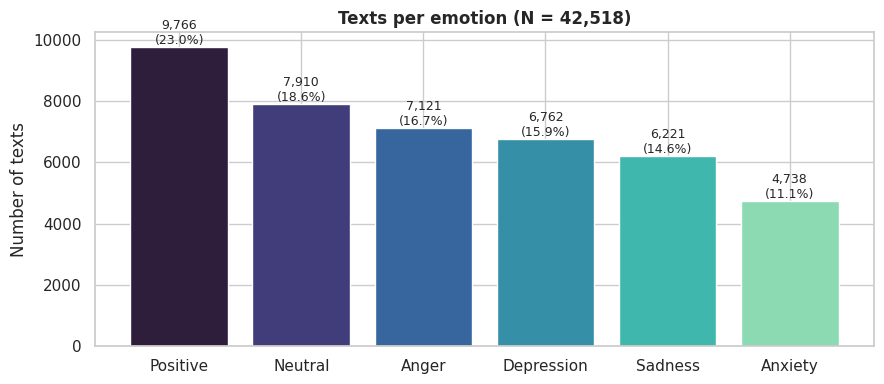

In [8]:
total_texts = mental_health_df.count()
emotion_distribution = (mental_health_df.groupBy("Emotion").count()
    .withColumn("pct", F.round(F.col("count") / total_texts * 100, 1))
    .orderBy(F.desc("count")))
emotion_distribution.show()

emotion_pd = emotion_distribution.toPandas()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(emotion_pd["Emotion"], emotion_pd["count"], color=sns.color_palette("mako", len(emotion_pd)))
ax.bar_label(bars, labels=[f"{c:,}\n({p}%)" for c, p in zip(emotion_pd["count"], emotion_pd["pct"])], fontsize=9)
ax.set_title(f"Texts per emotion (N = {total_texts:,})", fontweight="bold")
ax.set_ylabel("Number of texts")
plt.tight_layout(); plt.show()

## 3. Text: length and writing style per emotion

In [9]:
letters = F.length(F.regexp_replace("Text", "[^A-Za-z]", ""))
uppers = F.length(F.regexp_replace("Text", "[^A-Z]", ""))
text_metrics_df = (mental_health_df
    .withColumn("word_count", F.size(F.split(F.trim("Text"), r"\s+")))
    .withColumn("char_length", F.length("Text"))
    .withColumn("upper_ratio", F.when(letters > 0, uppers / letters).otherwise(0.0)))

text_metrics_df.select("word_count", "char_length").summary("mean", "stddev", "min", "25%", "50%", "75%", "max").show()

(text_metrics_df.groupBy("Emotion").agg(
        F.count("*").alias("texts"),
        F.round(F.avg("word_count"), 1).alias("avg_words"),
        F.percentile_approx("word_count", 0.5).alias("median_words"),
        F.max("word_count").alias("max_words"),
        F.round(F.avg((F.col("word_count") > 200).cast("int")) * 100, 1).alias("pct_over_200_words"),
        F.round(F.avg((F.col("upper_ratio") > 0).cast("int")) * 100, 1).alias("pct_with_capitals"))
    .orderBy(F.desc("avg_words"))
    .show())

+-------+-----------------+------------------+
|summary|       word_count|       char_length|
+-------+-----------------+------------------+
|   mean|45.92885366197846|232.48485347382285|
| stddev|91.29142910054735|463.89389931443054|
|    min|                1|                 3|
|    25%|               12|                60|
|    50%|               21|               107|
|    75%|               36|               184|
|    max|             1500|              7799|
+-------+-----------------+------------------+

+----------+-----+---------+------------+---------+------------------+-----------------+
|   Emotion|texts|avg_words|median_words|max_words|pct_over_200_words|pct_with_capitals|
+----------+-----+---------+------------+---------+------------------+-----------------+
|Depression| 6762|    176.4|         122|     1500|              29.6|             98.6|
|   Anxiety| 4738|     24.3|          23|       66|               0.0|              0.0|
|  Positive| 9766|     23.2|         

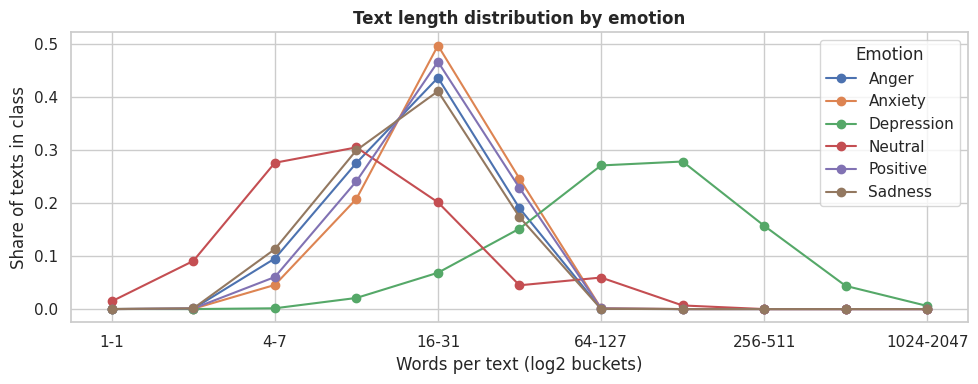

In [10]:
length_hist = (text_metrics_df
    .withColumn("bucket", F.floor(F.log2(F.col("word_count"))))
    .groupBy("Emotion", "bucket").count()
    .toPandas())
length_hist["share"] = length_hist["count"] / length_hist.groupby("Emotion")["count"].transform("sum")
pivot = length_hist.pivot(index="bucket", columns="Emotion", values="share").fillna(0).sort_index()
pivot.index = [f"{2**int(b)}-{2**(int(b) + 1) - 1}" for b in pivot.index]

ax = pivot.plot(kind="line", marker="o", figsize=(10, 4))
ax.set_title("Text length distribution by emotion", fontweight="bold")
ax.set_xlabel("Words per text (log2 buckets)"); ax.set_ylabel("Share of texts in class")
plt.tight_layout(); plt.show()

Depression posts are long, capitalised Reddit-style posts while most other classes are short lower-case sentences, so length alone could leak the label (tested in `GX_MLlib`).

## 4. Text: top terms per emotion

In [11]:
words_df = (mental_health_df
    .select("Emotion", F.explode(F.split(F.lower("Text"), "[^a-z]+")).alias("word"))
    .filter((F.length("word") > 2) & ~F.col("word").isin(U.EDA_STOPWORDS)))

rank_window = Window.partitionBy("Emotion").orderBy(F.desc("count"))
top_words = (words_df.groupBy("Emotion", "word").count()
    .withColumn("rank", F.row_number().over(rank_window))
    .filter("rank <= 8"))

(top_words.groupBy("Emotion")
    .agg(F.array_join(F.transform(F.sort_array(F.collect_list(F.struct("rank", "word"))), lambda s: s["word"]), ", ")
         .alias("top_8_terms"))
    .orderBy("Emotion")
    .show(truncate=False))

+----------+---------------------------------------------------------------+
|Emotion   |top_8_terms                                                    |
+----------+---------------------------------------------------------------+
|Anger     |hate, angry, hated, discouraged, whatever, people, time, way   |
|Anxiety   |surprised, shocked, worry, anxiety, still, time, people, little|
|Depression|life, cannot, people, time, depression, going, think, day      |
|Neutral   |time, people, good, work, day, going, still, back              |
|Positive  |love, happy, loved, time, life, people, make, beloved          |
|Sadness   |sad, depressed, melancholy, sadness, little, time, bit, think  |
+----------+---------------------------------------------------------------+



## 5. Network veracity: how many float-exported `Source` IDs can be matched to accounts before and after the repair

In [12]:
id_df = U.maybe_cache(twitter_graph_df.select(
    "Source", "Destination",
    U.normalize_twitter_id(F.col("Source")).alias("src"),
    U.normalize_twitter_id(F.col("Destination")).alias("dst"),
    F.to_timestamp("Relationship Date (UTC)").alias("relationship_ts"),
    F.col("Destination Followers").alias("dst_followers")))

total_edges = id_df.count()
raw_dest = id_df.select(F.col("Destination").alias("Source")).distinct()
fixed_dest = id_df.select(F.col("dst").alias("src")).distinct()

print(f"relationships:                          {total_edges:,}")
print(f"source in scientific notation:          {id_df.filter(U.is_scientific_notation(F.col('Source'))).count():,}")
print(f"source matches a destination (raw):     {id_df.join(raw_dest, 'Source', 'left_semi').count():,}")
print(f"source matches a destination (repaired):{id_df.join(fixed_dest, 'src', 'left_semi').count():,}")
print(f"self-interactions after repair:         {id_df.filter('src = dst').count():,}")

relationships:                          548,541
source in scientific notation:          323,071
source matches a destination (raw):     0
source matches a destination (repaired):308,469
self-interactions after repair:         175,956


## 6. Network volume: scale and degree distribution

In [13]:
social = id_df.filter("src <> dst")
nodes = social.select(F.col("src").alias("id")).union(social.select(F.col("dst").alias("id"))).distinct()
n_nodes, n_edges = nodes.count(), social.count()
n_pairs = social.select("src", "dst").distinct().count()
print(f"accounts: {n_nodes:,} | interactions: {n_edges:,} | distinct pairs: {n_pairs:,} | density: {n_pairs / (n_nodes * (n_nodes - 1)):.2e}")

out_degree = social.groupBy("src").agg(F.countDistinct("dst").alias("out_degree"))
in_degree = social.groupBy("dst").agg(F.countDistinct("src").alias("in_degree"))
out_degree.select("out_degree").summary("mean", "50%", "90%", "99%", "max").show()
in_degree.select("in_degree").summary("mean", "50%", "90%", "99%", "max").show()

accounts: 292,488 | interactions: 372,584 | distinct pairs: 332,289 | density: 3.88e-06
+-------+------------------+
|summary|        out_degree|
+-------+------------------+
|   mean|1.9606615607925513|
|    50%|                 1|
|    90%|                 4|
|    99%|                10|
|    max|               157|
+-------+------------------+

+-------+------------------+
|summary|         in_degree|
+-------+------------------+
|   mean|2.2197883682712733|
|    50%|                 1|
|    90%|                 3|
|    99%|                16|
|    max|              2033|
+-------+------------------+



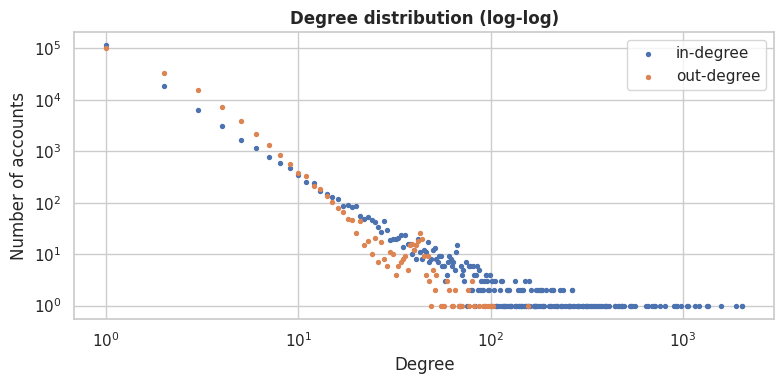

+-------------------+---------+
|dst                |in_degree|
+-------------------+---------+
|1915033663         |2033     |
|133938408          |2025     |
|1349149096909670000|1885     |
|91416107           |1573     |
|939091             |1349     |
|1446231057259430000|1340     |
|1326229737551910000|1218     |
|818893114979062000 |1158     |
|132339474          |1063     |
|1344356576786870000|1050     |
+-------------------+---------+
only showing top 10 rows
+---------------+------+
|Source Verified| count|
+---------------+------+
|           NULL| 39604|
|          False|508937|
+---------------+------+



In [14]:
in_freq = in_degree.groupBy("in_degree").count().toPandas()
out_freq = out_degree.groupBy("out_degree").count().toPandas()

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(in_freq["in_degree"], in_freq["count"], s=8, label="in-degree")
ax.scatter(out_freq["out_degree"], out_freq["count"], s=8, label="out-degree")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Degree"); ax.set_ylabel("Number of accounts")
ax.set_title("Degree distribution (log-log)", fontweight="bold")
ax.legend(); plt.tight_layout(); plt.show()

in_degree.orderBy(F.desc("in_degree")).show(10, truncate=False)
twitter_graph_df.groupBy("Source Verified").count().show()

## 7. Velocity: relationships recorded per day

+----------+----------+
|  min(day)|  max(day)|
+----------+----------+
|2013-01-27|2023-08-31|
+----------+----------+



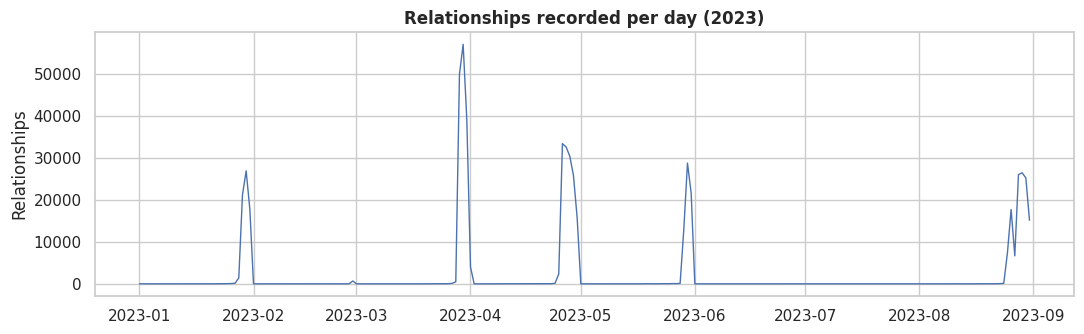

In [15]:
daily = id_df.groupBy(F.to_date("relationship_ts").alias("day")).count().orderBy("day")
daily.select(F.min("day"), F.max("day")).show()

daily_pd = daily.filter(F.col("day") >= "2023-01-01").toPandas()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily_pd["day"], daily_pd["count"], lw=1)
ax.set_title("Relationships recorded per day (2023)", fontweight="bold"); ax.set_ylabel("Relationships")
plt.tight_layout(); plt.show()

## 8. Spark SQL: length percentiles per emotion, longest posts, and the most-engaged accounts per follower tier

In [16]:
text_metrics_df.createOrReplaceTempView("texts")
social.createOrReplaceTempView("interactions")

spark.sql('''
    SELECT Emotion,
           percentile_approx(word_count, 0.5) AS median_words,
           percentile_approx(word_count, 0.9) AS p90_words
    FROM texts GROUP BY Emotion ORDER BY median_words DESC
''').show()

spark.sql('''
    WITH ranked AS (
        SELECT Emotion, word_count, substring(Text, 1, 70) AS snippet,
               ROW_NUMBER() OVER (PARTITION BY Emotion ORDER BY word_count DESC) AS rk
        FROM texts)
    SELECT Emotion, rk, word_count, snippet FROM ranked WHERE rk <= 2 ORDER BY Emotion, rk
''').show(truncate=False)

+----------+------------+---------+
|   Emotion|median_words|p90_words|
+----------+------------+---------+
|Depression|         122|      379|
|   Anxiety|          23|       41|
|  Positive|          21|       40|
|     Anger|          19|       38|
|   Sadness|          18|       37|
|   Neutral|          10|       38|
+----------+------------+---------+

+----------+---+----------+----------------------------------------------------------------------+
|Emotion   |rk |word_count|snippet                                                               |
+----------+---+----------+----------------------------------------------------------------------+
|Anger     |1  |68        |one day i had sunned my favourite shirt and was putting it back in the|
|Anger     |2  |64        |i need to act yes i know i can t write or think my way out of the comp|
|Anxiety   |1  |66        |i liked it when u called me when u tot i was stressed at work i liked |
|Anxiety   |2  |66        |i feel my heart be

In [17]:
spark.sql('''
    WITH inbound AS (
        SELECT dst AS account, COUNT(*) AS interactions, COUNT(DISTINCT src) AS distinct_senders,
               MAX(dst_followers) AS followers
        FROM interactions GROUP BY dst),
    tiered AS (
        SELECT *, CASE WHEN followers IS NULL THEN '0 unknown'
                       WHEN followers < 1000 THEN '1 micro (<1K)'
                       WHEN followers < 100000 THEN '2 mid (1K-100K)'
                       ELSE '3 macro (>100K)' END AS tier
        FROM inbound),
    ranked AS (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY tier ORDER BY distinct_senders DESC) AS rk FROM tiered)
    SELECT tier, rk, account, followers, distinct_senders, interactions
    FROM ranked WHERE rk <= 3 ORDER BY tier, rk
''').show(truncate=False)

+---------------+---+-------------------+---------+----------------+------------+
|tier           |rk |account            |followers|distinct_senders|interactions|
+---------------+---+-------------------+---------+----------------+------------+
|0 unknown      |1  |1349149096909670000|NULL     |1885            |2085        |
|0 unknown      |2  |1446231057259430000|NULL     |1340            |1421        |
|0 unknown      |3  |818893114979062000 |NULL     |1158            |1341        |
|1 micro (<1K)  |1  |361972447          |185.0    |87              |88          |
|1 micro (<1K)  |2  |1504036632080570000|901.0    |78              |79          |
|1 micro (<1K)  |3  |298959333          |430.0    |51              |58          |
|2 mid (1K-100K)|1  |1042832057867610000|31083.0  |400             |417         |
|2 mid (1K-100K)|2  |1107296448         |63722.0  |229             |270         |
|2 mid (1K-100K)|3  |2448356087         |47219.0  |220             |235         |
|3 macro (>100K)

**Takeaways:** classes are moderately imbalanced (Positive 23% vs Anxiety 11%); Depression texts are ~6x longer than the rest (median 122 vs 10–23 words); the raw graph is unusable until IDs are repaired; degrees follow a heavy-tailed hub structure.